# Задание 5. Ассоциативные правила и кластеризация (методы обучения без учителя)

Датасет `Unis.csv` «IT-выпускники: траектории трудоустройства», 8649 выпускников, 27 признаков.

Задача от руководства: понять, какие характеристики выпускника связаны с высокой стартовой зарплатой и быстрым трудоустройством, составить профиль «идеального кандидата», разделить факторы на обязательные и желательные и сравнить профиль для разработчиков, аналитиков и бизнес-информатиков.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from mlxtend.frequent_patterns import apriori, association_rules

RS = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

In [2]:
df = pd.read_csv("Unis.csv", sep=";", decimal=",")
print(df.shape)
df.head()

(8649, 27)


,id,year_graduation,region,city_type,university_type,it_direction,specialization,degree,exam_math,exam_russian,...,internship_company_type,internship_field,employment_status,first_salary,salary_in_field,job_search_time,gender,age_at_graduation,has_job_offer_before_graduation,expectation_salary
0,1,2021,Центральный,областной_центр,классический,аналитика,бизнес_аналитика,бакалавр,93.0,72.0,...,аутсорс,по_специальности,работает_по_специальности,104856.0,1.0,1.0,М,22,0,107863.0
1,2,2025,Южный,областной_центр,классический,разработка,веб-разработка,бакалавр,65.0,74.0,...,аутсорс,по_специальности,работает_по_специальности,NaN,1.0,NaN,М,22,1,91994.0
2,3,2023,Северо-Западный,мегаполис,национальный_исследовательский,разработка,frontend,бакалавр,84.0,80.0,...,стартап,по_специальности,не_работает,76154.0,0.0,0.0,М,22,1,93706.0
3,4,2023,Приволжский,мегаполис,национальный_исследовательский,аналитика,data_аналитика,магистр,64.0,70.0,...,NaN,NaN,работает_по_специальности,82017.0,1.0,3.0,М,25,1,NaN
4,5,2020,Южный,малый_город,национальный_исследовательский,разработка,веб-разработка,бакалавр,63.0,69.0,...,стартап,не_по_специальности,работает_по_специальности,83199.0,1.0,0.0,М,21,0,NaN


## Чистка данных

Проверяю значения на соответствие описанию датасета.

In [3]:
limits = {
    "exam_math": (0, 100), "exam_russian": (0, 100), "exam_informatics": (0, 100),
    "gpa": (3, 5), "gpa_relative": (0, 100), "job_search_time": (0, 18),
    "age_at_graduation": (19, 35), "first_salary": (15_000, 400_000),
}
for c, (lo, hi) in limits.items():
    bad = ~df[c].between(lo, hi) & df[c].notna()
    print(f"{c:20s} вне [{lo}, {hi}]: {bad.sum():3d}   примеры: {sorted(df.loc[bad, c].unique())[:6]}")
print()
print(df["region"].value_counts())

exam_math            вне [0, 100]:  42   примеры: [np.float64(150.0), np.float64(200.0)]
exam_russian         вне [0, 100]:   0   примеры: []
exam_informatics     вне [0, 100]:   0   примеры: []
gpa                  вне [3, 5]:  42   примеры: [np.float64(1.2), np.float64(5.9), np.float64(6.5)]
gpa_relative         вне [0, 100]:   0   примеры: []
job_search_time      вне [0, 18]:  34   примеры: [np.float64(-5.0), np.float64(99.0), np.float64(120.0)]
age_at_graduation    вне [19, 35]:  37   примеры: [np.int64(12), np.int64(45), np.int64(60)]
first_salary         вне [15000, 400000]:  48   примеры: [np.float64(999999.0), np.float64(1500000.0), np.float64(2500000.0)]

region
Центральный         1697
Приволжский         1570
Южный               1315
Сибирский           1144
Северо-Западный     1019
Уральский           1011
Дальневосточный      851
СПб                   13
ДВР                   11
УрФО                   9
Москва и область       9
Name: count, dtype: int64


Ошибки ввода:

- `exam_math` = 200 при максимуме 100;
- `gpa` от 1.2 до 6.5 при шкале 3.0–5.0;
- `job_search_time` отрицательное или 120 месяцев при шкале 0–18;
- `age_at_graduation` 12 или 60 лет;
- `first_salary` до 2.5 млн руб. Такие значения по одному на несколько тысяч и похожи на лишний ноль.

Такие значения заменяю на пропуск. Регион записан по-разному: «СПб», «ДВР», «УрФО», «Москва и область» свожу к федеральным округам.

In [ ]:
for c, (lo, hi) in limits.items():
    df.loc[~df[c].between(lo, hi), c] = np.nan

df["region"] = df["region"].replace({"СПб": "Северо-Западный", "ДВР": "Дальневосточный",
                                     "УрФО": "Уральский", "Москва и область": "Центральный"})

# если стажировки не было, тип компании и соответствие специальности пустые – это не пропуск
df.loc[df["internship"] == 0, ["internship_company_type", "internship_field"]] = "нет_стажировки"
df["github_quality"] = df["github_quality"].fillna(df["has_github"].map({0: "нет", 1: "нет_данных"}))

salary_known = df["first_salary"].notna() 
df.isna().sum()[lambda s: s > 0]

exam_math              899
exam_russian           925
exam_informatics      1020
gpa                    955
gpa_relative           941
internship_field       437
employment_status     1012
first_salary           973
salary_in_field        988
job_search_time       1046
age_at_graduation       37
expectation_salary     992
dtype: int64

Оставшиеся пропуски – около 10% в каждом столбце, без видимой закономерности. Удаление всех строк с пропусками выбросило бы больше половины выборки, поэтому числовые признаки заполняю медианой, категориальные – значением `нет_данных`.

In [5]:
num_cols = ["exam_math", "exam_russian", "exam_informatics", "gpa", "gpa_relative",
            "first_salary", "job_search_time", "expectation_salary", "age_at_graduation"]
for c in num_cols + ["salary_in_field"]:
    df[c] = df[c].fillna(df[c].median())
df["exam_total"] = df[["exam_math", "exam_russian", "exam_informatics"]].sum(axis=1)
for c in df.select_dtypes(include="str").columns:
    df[c] = df[c].fillna("нет_данных")
print("пропусков осталось:", df.isna().sum().sum())

пропусков осталось: 0


## 1.2. Стандартизация и k-Means

Разделяю данные на признаки X и «целевую» переменную y. В кластеризации y не участвует, по нему потом проверяю, совпадают ли кластеры с направлением подготовки. В качестве y беру `it_direction`.

Для кластеризации беру числовые и бинарные признаки. Стандартизация: $z = (x - u) / s$.

In [6]:
cluster_cols = ["exam_math", "exam_russian", "exam_informatics", "gpa", "gpa_relative",
                "has_github", "internship", "has_job_offer_before_graduation",
                "first_salary", "job_search_time", "expectation_salary", "age_at_graduation"]
X = df[cluster_cols]
y = df["it_direction"]

scaler = StandardScaler()
Z = scaler.fit_transform(X)
print("средние:", Z.mean(axis=0).round(3))
print("СКО:   ", Z.std(axis=0).round(3))

средние: [ 0.  0. -0. -0. -0. -0. -0.  0.  0. -0. -0. -0.]
СКО:    [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [7]:
ks = range(1, 11)
wcss, sil = [], []
models = {}
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(Z)
    models[k] = km
    wcss.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_, sample_size=3000, random_state=RS) if k > 1 else np.nan)

elbow = pd.DataFrame({"k": list(ks), "WCSS": wcss, "снижение WCSS, %": np.r_[np.nan, -np.diff(wcss) / wcss[:-1] * 100],
                      "silhouette": sil}).set_index("k")
elbow.round(3)

,WCSS,"снижение WCSS, %",silhouette
k,,,
1,103788.000,NaN,NaN
2,84555.043,18.531,0.162
3,77716.397,8.088,0.119
4,72509.079,6.700,0.113
5,69442.507,4.229,0.110
6,67171.452,3.270,0.103
7,65235.807,2.882,0.105
8,63777.062,2.236,0.093
9,62461.557,2.063,0.088


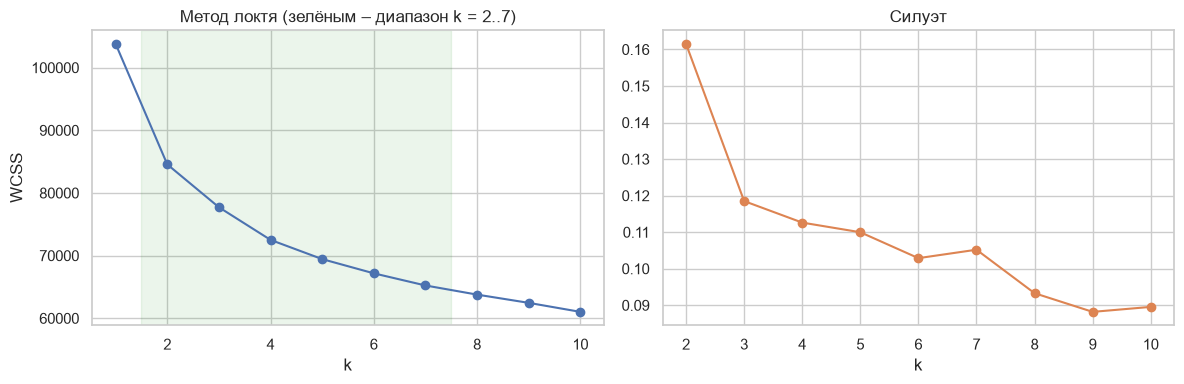

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), wcss, "o-"); ax[0].axvspan(1.5, 7.5, alpha=.08, color="green")
ax[0].set_xlabel("k"); ax[0].set_ylabel("WCSS"); ax[0].set_title("Метод локтя (зелёным – диапазон k = 2..7)")
ax[1].plot(list(ks)[1:], sil[1:], "o-", color="C1"); ax[1].set_xlabel("k"); ax[1].set_title("Силуэт")
plt.tight_layout(); plt.show()


Чёткого локтя на графике нет, WCSS убывает плавно. Переход от 1 к 2 кластерам снижает WCSS на 18.5%, от 2 к 3 – на 8.1%, от 3 к 4 – на 6.7%. Дальше каждый новый кластер даёт меньше 5% (4.2%, 3.3%, 2.9%). Изгиб приходится на k = 4, его и беру.

Силуэт максимален при k = 2 (0.162), но и там он низкий: кластеры сильно перекрываются. Два кластера просто делят выпускников на «сильных» и «слабых». При k = 4 видно, что оценки и практический опыт – разные оси (см. ниже).


In [9]:
K = 4
km = models[K]
df["cluster"] = km.labels_
print(df["cluster"].value_counts().sort_index())
print("ARI кластеров и it_direction:", round(adjusted_rand_score(y, km.labels_), 3))
pd.crosstab(df["cluster"], y, normalize="index").round(2)

cluster
0    1901
1    1937
2    2479
3    2332
Name: count, dtype: int64
ARI кластеров и it_direction: 0.056


it_direction,аналитика,бизнес-информатика,разработка
cluster,,,
0,0.44,0.36,0.20
1,0.20,0.07,0.72
2,0.42,0.23,0.35
3,0.32,0.14,0.54


## 1.3. Визуализация кластеров

Проецирую 12-мерное пространство на две главные компоненты, затем смотрю центроиды в стандартизованных единицах: 0 – среднее по выборке, +1 – на одно СКО выше.

доля объяснённой дисперсии: [0.287 0.136]


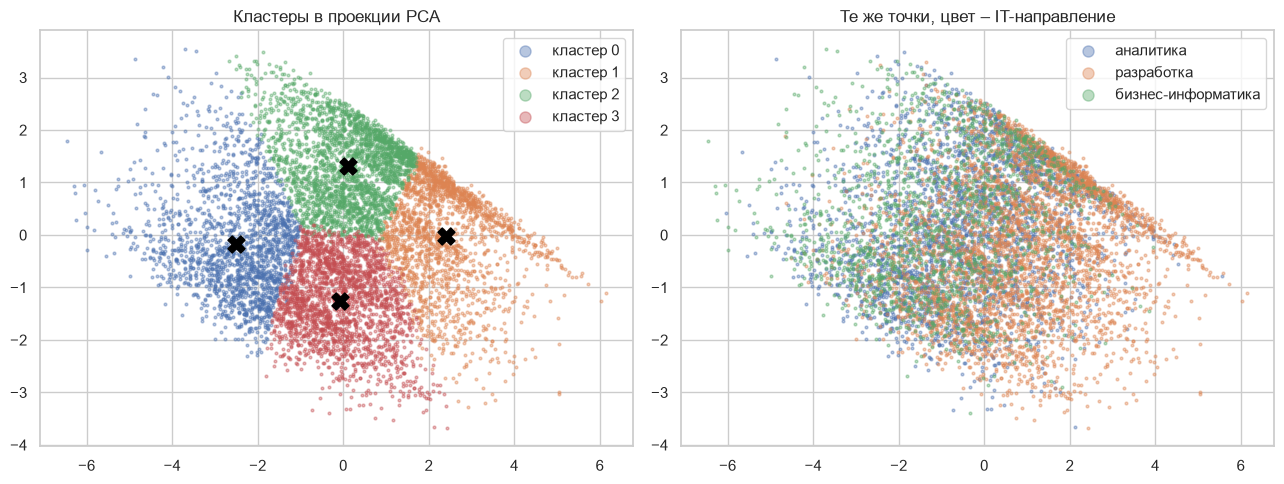

In [10]:
pca = PCA(n_components=2, random_state=RS)
P = pca.fit_transform(Z)
print("доля объяснённой дисперсии:", pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c in range(K):
    m = km.labels_ == c
    ax[0].scatter(P[m, 0], P[m, 1], s=4, alpha=.4, label=f"кластер {c}")
C = pca.transform(km.cluster_centers_)
ax[0].scatter(C[:, 0], C[:, 1], c="black", marker="X", s=150)
ax[0].set_title("Кластеры в проекции PCA"); ax[0].legend(markerscale=4)
for d in y.unique():
    m = (y == d).values
    ax[1].scatter(P[m, 0], P[m, 1], s=4, alpha=.4, label=d)
ax[1].set_title("Те же точки, цвет – IT-направление"); ax[1].legend(markerscale=4)
plt.tight_layout(); plt.show()

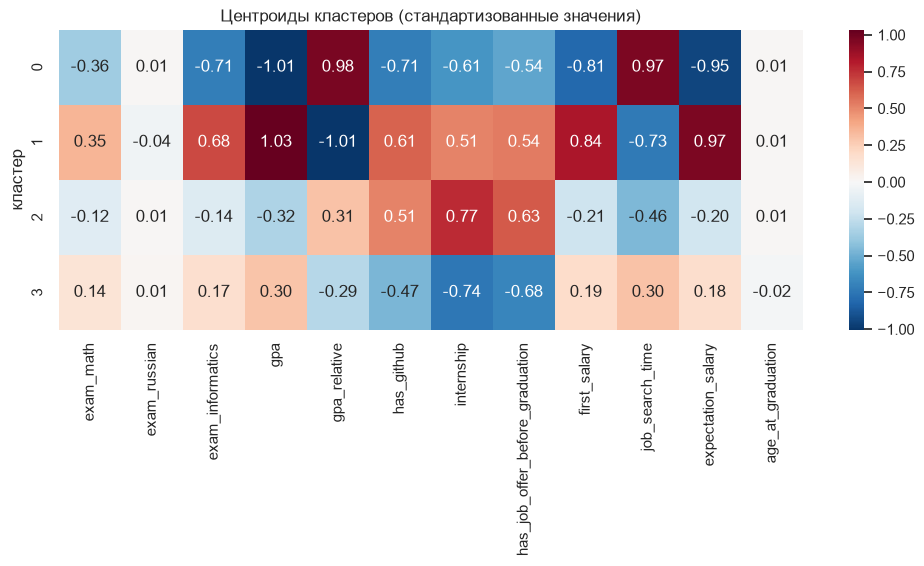

In [11]:
centers = pd.DataFrame(km.cluster_centers_, columns=cluster_cols)
plt.figure(figsize=(12, 0.6 * K + 1.5))
sns.heatmap(centers, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Центроиды кластеров (стандартизованные значения)"); plt.ylabel("кластер")
plt.show()

In [12]:
profile = df.groupby("cluster").agg(
    n=("id", "size"),
    gpa=("gpa", "mean"), exam_total=("exam_total", "mean"),
    github=("has_github", "mean"), internship=("internship", "mean"),
    offer=("has_job_offer_before_graduation", "mean"),
    salary=("first_salary", "median"), expectation=("expectation_salary", "median"),
    search_months=("job_search_time", "mean"), age=("age_at_graduation", "mean"),
)
profile["доля"] = profile["n"] / len(df)
profile.round(2)

,n,gpa,exam_total,github,internship,offer,salary,expectation,search_months,age,доля
cluster,,,,,,,,,,,
0,1901,3.71,210.45,0.20,0.16,0.26,67253.0,68748.0,3.66,22.71,0.22
1,1937,4.32,237.55,0.85,0.72,0.80,100892.0,98904.0,0.79,22.70,0.22
2,2479,3.92,221.19,0.81,0.85,0.85,82155.0,82528.0,1.26,22.70,0.29
3,2332,4.10,228.55,0.32,0.10,0.19,84470.0,84608.0,2.53,22.65,0.27



Первые две главные компоненты объясняют 42% дисперсии (28.7% + 13.6%). На проекции видны чёткие границы, но провёл их сам k-Means: облако точек сплошное, без разрывов, и силуэт 0.11 это подтверждает.

| Кластер | Доля | Портрет | Медиана ЗП | Поиск работы |
|---|---|---|---|---|
| 1 – «сильные» | 22% | GPA 4.32, ЕГЭ 238, GitHub у 85%, стажировка у 72%, оффер до выпуска у 80% | 101 тыс. | 0.8 мес. |
| 2 – «практики» | 29% | GPA 3.92, ЕГЭ 221, GitHub у 81%, стажировка у 85%, оффер у 85% | 82 тыс. | 1.3 мес. |
| 3 – «отличники без практики» | 27% | GPA 4.10, ЕГЭ 229, GitHub у 32%, стажировка у 10%, оффер у 19% | 84 тыс. | 2.5 мес. |
| 0 – «без опыта и оценок» | 22% | GPA 3.71, ЕГЭ 210, GitHub у 20%, стажировка у 16%, оффер у 26% | 67 тыс. | 3.7 мес. |

Самое интересное – кластеры 2 и 3. Зарплата у них почти одинаковая (82 и 84 тыс.), но «практики» находят работу вдвое быстрее. Похоже, оценки сильнее связаны с уровнем зарплаты, а стажировка и портфолио – со скоростью трудоустройства. Проверю это ниже на правилах.

С направлением подготовки кластеры почти не совпадают: ARI = 0.056. Исключение – кластер 1, в нём 72% разработчиков. Возраст во всех кластерах одинаковый (22.7 года), на разбиение он не влияет.


## 1.4. Apriori: поиск особых случаев

Apriori работает с транзакциями. Каждый выпускник – транзакция, элементы – значения его признаков. Числовые признаки разбиваю на интервалы:

- `first_salary`, `expectation_salary`, `gpa`, `exam_total` – на три равные по численности группы (низкая / средняя / высокая);
- `job_search_time`: «быстро» (0–1 мес.), «средне» (2–3), «долго» (4 и больше).

In [13]:
items = pd.DataFrame(index=df.index)
for c in ["city_type", "university_type", "it_direction", "degree", "github_quality",
          "internship_company_type", "internship_field", "employment_status", "gender"]:
    items[c] = df[c]
# без стажировки поле «соответствие специальности» не имеет смысла, иначе получим тавтологию
# «нет_стажировки → нет_стажировки» с confidence 1
items.loc[df["internship"] == 0, "internship_field"] = np.nan
items["offer_before_grad"] = df["has_job_offer_before_graduation"].map({1: "да", 0: "нет"})
for c in ["first_salary", "expectation_salary", "gpa", "exam_total"]:
    items[c] = pd.qcut(df[c], 3, labels=["низк", "сред", "выс"]).astype(str)
items["job_search"] = pd.cut(df["job_search_time"], [-1, 1, 3, 100], labels=["быстро", "средне", "долго"]).astype(str)

basket = pd.get_dummies(items, prefix_sep="=").astype(bool)
print(basket.shape)
basket.mean().sort_values(ascending=False).head(10).round(3)

(8649, 47)


gender=М                                       0.634
employment_status=работает_по_специальности    0.550
degree=бакалавр                                0.544
internship_company_type=нет_стажировки         0.534
offer_before_grad=да                           0.530
offer_before_grad=нет                          0.470
city_type=областной_центр                      0.460
it_direction=разработка                        0.451
github_quality=нет                             0.448
job_search=средне                              0.414
dtype: float64

In [14]:
freq = apriori(basket, min_support=0.02, use_colnames=True, max_len=4)
rules = association_rules(freq, num_itemsets=len(basket), metric="lift", min_threshold=1.0)

fmt = lambda s: ", ".join(sorted(s))
rules["lhs"] = rules["antecedents"].apply(fmt)
rules["rhs"] = rules["consequents"].apply(fmt)
cols = ["lhs", "rhs", "support", "confidence", "lift", "antecedent support"]
print("частых наборов:", len(freq), "  правил с lift > 1:", len(rules))

частых наборов: 24057   правил с lift > 1: 177824


Строю три набора правил с разными порогами. Каждый порог отсекает правила по своему критерию:

1. **Support ≥ 0.25** – частые закономерности, которые касаются хотя бы четверти выпускников.
2. **Confidence ≥ 0.75, support ≥ 0.03** – надёжные правила: если выполнено условие, следствие верно в 3 случаях из 4.
3. **Lift ≥ 1.8, support ≥ 0.02** – сильные зависимости, где условие почти вдвое повышает вероятность следствия.

Пороги подобраны так, чтобы в каждом наборе оставалось от нескольких десятков до нескольких сотен правил: при более низком пороге правил тысячи и их невозможно просмотреть.

In [15]:
sets = {
    "Support ≥ 0.25": rules[rules["support"] >= 0.25],
    "Confidence ≥ 0.75": rules[(rules["confidence"] >= 0.75) & (rules["support"] >= 0.03)],
    "Lift ≥ 1.8": rules[(rules["lift"] >= 1.8) & (rules["support"] >= 0.02)],
}
for name, r in sets.items():
    print(f"{name:18s}: {len(r):5d} правил")

Support ≥ 0.25    :    30 правил
Confidence ≥ 0.75 :   862 правил
Lift ≥ 1.8        : 13694 правил


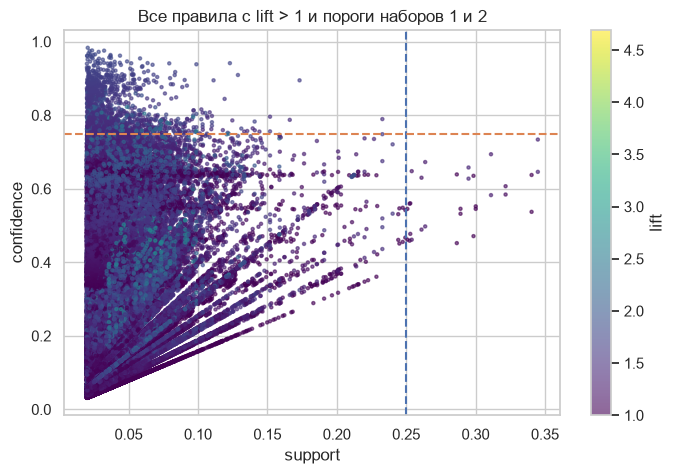

In [16]:
plt.figure(figsize=(8, 5))
sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], s=5, cmap="viridis", alpha=.6)
plt.colorbar(sc, label="lift"); plt.xlabel("support"); plt.ylabel("confidence")
plt.axvline(0.25, ls="--", c="C0"); plt.axhline(0.75, ls="--", c="C1")
plt.title("Все правила с lift > 1 и пороги наборов 1 и 2")
plt.show()

## 1.5. Как меняется ТОП-5 в зависимости от метрики

Из каждого набора беру 5 лучших правил по его метрике. В правилах с поддержкой убираю зеркальные пары (A → B и B → A имеют одинаковую поддержку).

In [17]:
def top5(r, metric):
    r = r.sort_values([metric, "lift"], ascending=False).copy()
    r["pair"] = r.apply(lambda x: frozenset(x["antecedents"] | x["consequents"]), axis=1)
    return r.drop_duplicates("pair").head(5)[cols].round(3)

print("ТОП-5 по Support"); display(top5(sets["Support ≥ 0.25"], "support"))

ТОП-5 по Support


,lhs,rhs,support,confidence,lift,antecedent support
649,offer_before_grad=нет,internship_company_type=нет_стажировки,0.345,0.734,1.374,0.470
646,internship_company_type=нет_стажировки,gender=М,0.340,0.638,1.006,0.534
796,offer_before_grad=да,employment_status=работает_по_специальности,0.322,0.607,1.103,0.530
510,internship_company_type=нет_стажировки,github_quality=нет,0.311,0.583,1.300,0.534
384,employment_status=работает_по_специальности,degree=бакалавр,0.300,0.545,1.003,0.550


In [18]:
print("ТОП-5 по Confidence"); display(top5(sets["Confidence ≥ 0.75"], "confidence"))

ТОП-5 по Confidence


,lhs,rhs,support,confidence,lift,antecedent support
156339,"employment_status=не_работает, job_search=долго, offer_before_grad=нет",internship_company_type=нет_стажировки,0.032,0.976,1.827,0.033
117592,"it_direction=разработка, job_search=долго, offer_before_grad=нет",internship_company_type=нет_стажировки,0.037,0.964,1.805,0.038
20481,"employment_status=не_работает, job_search=долго",internship_company_type=нет_стажировки,0.044,0.962,1.802,0.046
159649,"expectation_salary=сред, job_search=долго, offer_before_grad=нет",internship_company_type=нет_стажировки,0.037,0.961,1.800,0.039
145368,"employment_status=не_работает, github_quality=нет, job_search=долго",internship_company_type=нет_стажировки,0.036,0.957,1.792,0.038


In [19]:
print("ТОП-5 по Lift"); display(top5(sets["Lift ≥ 1.8"], "lift"))

ТОП-5 по Lift


,lhs,rhs,support,confidence,lift,antecedent support
161862,"first_salary=низк, internship_company_type=стартап","expectation_salary=низк, internship_field=по_специальности",0.023,0.405,4.690,0.056
155038,"expectation_salary=выс, internship_company_type=аутсорс","first_salary=выс, internship_field=по_специальности",0.025,0.462,3.996,0.053
161808,"expectation_salary=выс, internship_company_type=стартап","first_salary=выс, internship_field=по_специальности",0.032,0.445,3.849,0.071
155108,"gpa=выс, internship_company_type=аутсорс","exam_total=выс, internship_field=по_специальности",0.020,0.397,3.564,0.051
155065,"expectation_salary=выс, internship_field=по_специальности","gpa=выс, internship_company_type=аутсорс",0.021,0.178,3.483,0.117


Правила выше в основном описывают «устройство» данных. Для задачи руководства полезнее правила, у которых в правой части стоит высокая зарплата или быстрое трудоустройство. Из левой части убираю признаки-результаты (статус занятости, зарплату, время поиска), иначе правило будет «высокая зарплата → работает по специальности», которое ничего не говорит о кандидате до найма.

In [20]:
outcome_prefix = ("first_salary=", "employment_status=", "job_search=", "expectation_salary=")
is_candidate_lhs = rules["antecedents"].apply(lambda s: not any(i.startswith(outcome_prefix) for i in s))

def target_rules(target, min_conf=0.0, n=10):
    r = rules[is_candidate_lhs & (rules["rhs"] == target) & (rules["confidence"] >= min_conf)]
    return r.sort_values("lift", ascending=False).head(n)[cols].round(3)

print("Базовая доля высокой зарплаты:", round(basket["first_salary=выс"].mean(), 3))
display(target_rules("first_salary=выс"))

Базовая доля высокой зарплаты: 0.333


,lhs,rhs,support,confidence,lift,antecedent support
36239,"city_type=мегаполис, gpa=выс, it_direction=разработка",first_salary=выс,0.045,0.710,2.130,0.063
38199,"city_type=мегаполис, github_quality=базовое, gpa=выс",first_salary=выс,0.021,0.667,2.000,0.031
36102,"city_type=мегаполис, it_direction=разработка, offer_before_grad=да",first_salary=выс,0.048,0.665,1.995,0.072
36265,"city_type=мегаполис, exam_total=выс, it_direction=разработка",first_salary=выс,0.034,0.656,1.969,0.051
116119,"github_quality=продвинутое, gpa=выс, it_direction=разработка",first_salary=выс,0.031,0.652,1.957,0.048
34468,"city_type=мегаполис, it_direction=разработка, university_type=отраслевой",first_salary=выс,0.021,0.650,1.949,0.032
118562,"gpa=выс, internship_company_type=стартап, it_direction=разработка",first_salary=выс,0.027,0.648,1.945,0.042
42206,"city_type=мегаполис, gpa=выс, offer_before_grad=да",first_salary=выс,0.040,0.648,1.944,0.061
35585,"city_type=мегаполис, github_quality=базовое, it_direction=разработка",first_salary=выс,0.025,0.645,1.935,0.039
41494,"city_type=мегаполис, gender=Ж, gpa=выс",first_salary=выс,0.023,0.634,1.903,0.037


In [21]:
print("Базовая доля быстрого поиска (0-1 мес.):", round(basket["job_search=быстро"].mean(), 3))
display(target_rules("job_search=быстро"))

Базовая доля быстрого поиска (0-1 мес.): 0.392


,lhs,rhs,support,confidence,lift,antecedent support
152057,"github_quality=продвинутое, gpa=выс, internship_field=по_специальности",job_search=быстро,0.026,0.821,2.094,0.032
154599,"exam_total=выс, gpa=выс, internship_company_type=BigTech",job_search=быстро,0.023,0.819,2.089,0.028
155722,"gender=М, gpa=выс, internship_company_type=аутсорс",job_search=быстро,0.025,0.818,2.087,0.031
116997,"gpa=выс, internship_company_type=аутсорс, it_direction=разработка",job_search=быстро,0.027,0.814,2.076,0.034
117011,"exam_total=выс, internship_company_type=аутсорс, it_direction=разработка",job_search=быстро,0.022,0.813,2.073,0.027
113374,"github_quality=базовое, internship_company_type=аутсорс, it_direction=разработка",job_search=быстро,0.021,0.806,2.057,0.026
163302,"exam_total=выс, gpa=выс, internship_company_type=стартап",job_search=быстро,0.027,0.803,2.047,0.034
155997,"exam_total=выс, gpa=выс, internship_company_type=аутсорс",job_search=быстро,0.022,0.801,2.043,0.028
166913,"exam_total=выс, gpa=выс, internship_field=по_специальности",job_search=быстро,0.049,0.800,2.039,0.061
95992,"gpa=выс, internship_field=по_специальности, university_type=отраслевой",job_search=быстро,0.024,0.796,2.031,0.030



#### 1.5. Как меняется ТОП-5 в зависимости от метрики

**По Support** в топ попадают правила о самых частых значениях. «Нет оффера → нет стажировки» (confidence 0.73) осмысленно. «Мужчина → нет стажировки» имеет lift 1.006, то есть признаки независимы: правило попало в топ только потому, что мужчин 63%, а выпускников без стажировки 53%. Support показывает, что часто встречается, а не что связано.

**По Confidence** все пять правил ведут к «нет стажировки» с confidence 0.96–0.98: «не работает + долго искал + нет оффера → не было стажировки». Правило логичное, но причинность в нём перевёрнута: отсутствие стажировки было до выпуска, а безработица – её следствие. Confidence любит частые следствия: «нет стажировки» встречается у половины выборки, и правило с ним легко набирает высокую достоверность.

**По Lift** значения самые высокие (3.5–4.7), но support всего 2–3%, и правила выглядят странно: «ожидал низкую зарплату + стажировка по специальности → низкая зарплата + стажировка в стартапе». На то есть две причины:
1. Ожидаемая и реальная зарплата коррелируют на 0.76, поэтому `expectation_salary` и `first_salary` почти всегда входят в одно правило.
2. В правой части два элемента сразу, их совместная частота мала, и lift завышается. На 2% выборки такое правило легко получить случайно.

**Самые логичные** правила получаются, если зафиксировать правую часть на результате:
- «мегаполис + GPA в верхней трети + разработка → высокая зарплата»: confidence 0.71 при базовой доле 0.33, lift 2.13, 4.5% выпускников;
- «продвинутый GitHub + высокий GPA + стажировка по специальности → нашёл работу за 0–1 мес.»: confidence 0.82 при базовой доле 0.39, lift 2.09.

**Странности в самих данных:**
- у 1094 выпускников со статусом «не работает» указана первая зарплата;
- медианный разрыв между ожидаемой и реальной зарплатой около нуля, хотя руководство жалуется именно на этот разрыв (подробнее в профиле кандидата ниже).


## Профиль «идеального кандидата»

Для каждого фактора считаю долю выпускников с высокой зарплатой (верхняя треть) среди тех, у кого фактор есть и у кого его нет, отдельно по направлениям. Разница в процентных пунктах показывает силу фактора.

То же самое считаю для быстрого трудоустройства (0–1 месяц поиска).

Правило классификации факторов:

- **обязательный** – с фактором доля высокой зарплаты или быстрого трудоустройства хотя бы вдвое выше, чем без него (отношение долей RR ≥ 2);
- **желательный** – фактор повышает одну из долей на 5 п.п. и больше;
- остальные – «не влияет».

Отношение долей беру вместо порога по абсолютной доле, потому что базовый уровень у направлений разный: у бизнес-информатиков высокая зарплата встречается реже, и абсолютный порог объявил бы обязательным почти любой фактор.

In [22]:
df["high_salary"] = (items["first_salary"] == "выс").astype(int)
df["fast_job"] = (items["job_search"] == "быстро").astype(int)
factors = {
    "стажировка": df["internship"] == 1,
    "стажировка в BigTech": df["internship_company_type"] == "BigTech",
    "стажировка по специальности": df["internship_field"] == "по_специальности",
    "GitHub продвинутый": df["github_quality"] == "продвинутое",
    "есть GitHub": df["has_github"] == 1,
    "оффер до выпуска": df["has_job_offer_before_graduation"] == 1,
    "GPA в верхней трети": items["gpa"] == "выс",
    "ЕГЭ в верхней трети": items["exam_total"] == "выс",
    "нац. исследовательский вуз": df["university_type"] == "национальный_исследовательский",
    "мегаполис": df["city_type"] == "мегаполис",
    "магистр": df["degree"] == "магистр",
}
rows = []
for d in ["разработка", "аналитика", "бизнес-информатика"]:
    m_d = df["it_direction"] == d
    for f, m in factors.items():
        with_f = df.loc[m_d & m, "high_salary"].mean()
        without = df.loc[m_d & ~m, "high_salary"].mean()
        fast_with = df.loc[m_d & m, "fast_job"].mean()
        fast_without = df.loc[m_d & ~m, "fast_job"].mean()
        rows.append({"направление": d, "фактор": f, "доля выс. ЗП с фактором": with_f,
                     "без фактора": without, "разница, п.п.": (with_f - without) * 100,
                     "RR зарплата": with_f / without,
                     "быстрый поиск: с фактором": fast_with, "без фактора ": fast_without,
                     "быстрый поиск: разница, п.п.": (fast_with - fast_without) * 100,
                     "RR быстрый поиск": fast_with / fast_without})
eff = pd.DataFrame(rows)

def kind(r):
    if r["RR зарплата"] >= 2 or r["RR быстрый поиск"] >= 2:
        return "обязательный"
    if r["разница, п.п."] >= 5 or r["быстрый поиск: разница, п.п."] >= 5:
        return "желательный"
    return "не влияет"
eff["тип"] = eff.apply(kind, axis=1)
eff.round(2).sort_values(["направление", "тип", "разница, п.п."], ascending=[True, False, False])

,направление,фактор,доля выс. ЗП с фактором,без фактора,"разница, п.п.",RR зарплата,быстрый поиск: с фактором,без фактора,"быстрый поиск: разница, п.п.",RR быстрый поиск,тип
15,аналитика,есть GitHub,0.31,0.17,13.62,1.80,0.45,0.17,27.46,2.59,обязательный
16,аналитика,оффер до выпуска,0.28,0.21,6.96,1.34,0.43,0.21,21.67,2.02,обязательный
13,аналитика,стажировка по специальности,0.27,0.23,3.58,1.15,0.55,0.22,32.33,2.46,обязательный
11,аналитика,стажировка,0.26,0.23,3.45,1.15,0.56,0.12,43.94,4.79,обязательный
12,аналитика,стажировка в BigTech,0.22,0.25,-2.77,0.89,0.58,0.28,29.74,2.05,обязательный
21,аналитика,магистр,0.23,0.25,-1.97,0.92,0.33,0.32,1.16,1.04,не влияет
19,аналитика,нац. исследовательский вуз,0.23,0.25,-2.37,0.91,0.32,0.32,-0.35,0.99,не влияет
20,аналитика,мегаполис,0.36,0.19,17.10,1.88,0.33,0.32,1.06,1.03,желательный
17,аналитика,GPA в верхней трети,0.35,0.21,14.62,1.70,0.50,0.26,23.87,1.90,желательный
14,аналитика,GitHub продвинутый,0.30,0.23,7.03,1.31,0.44,0.29,14.46,1.49,желательный


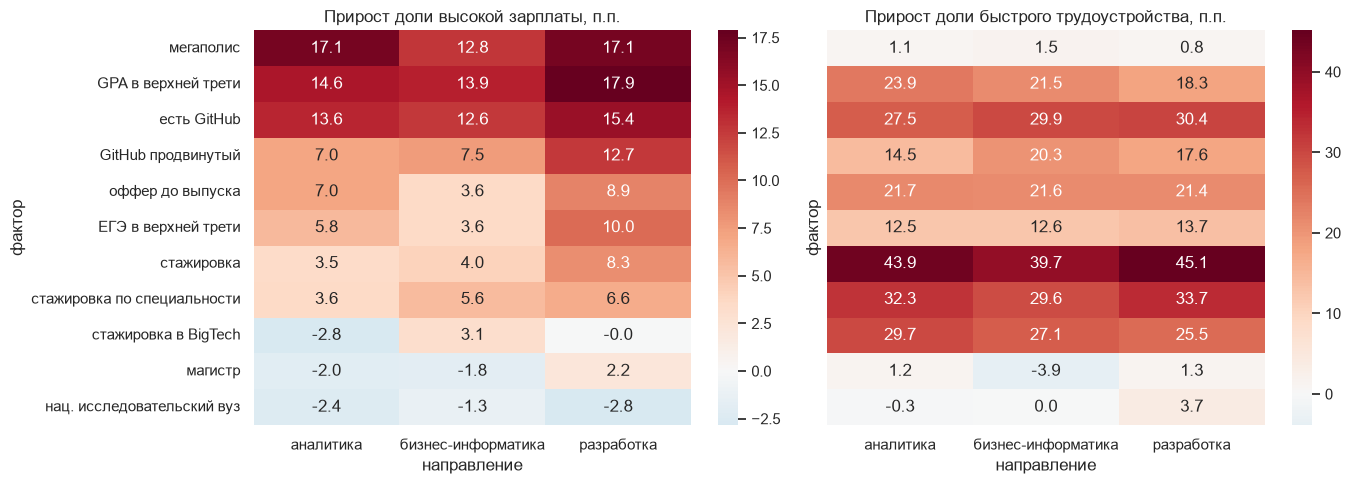

In [23]:
piv = eff.pivot(index="фактор", columns="направление", values="разница, п.п.")
piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.heatmap(piv, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax[0])
ax[0].set_title("Прирост доли высокой зарплаты, п.п.")
piv2 = eff.pivot(index="фактор", columns="направление", values="быстрый поиск: разница, п.п.").loc[piv.index]
sns.heatmap(piv2, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax[1])
ax[1].set_title("Прирост доли быстрого трудоустройства, п.п.")
plt.tight_layout(); plt.show()

In [24]:
print("Медианная первая зарплата по направлениям:")
print(df.groupby("it_direction")["first_salary"].median())
print()
m = salary_known & (df["expectation_salary"] != df["expectation_salary"].median())
gap = (df["expectation_salary"] - df["first_salary"]) / df["first_salary"]
print("корреляция ожидаемой и реальной зарплаты:", round(df.loc[m, ["expectation_salary", "first_salary"]].corr().iloc[0, 1], 3))
gap_tab = pd.DataFrame({
    "медиана разрыва, %": gap[m].groupby(df["it_direction"]).median() * 100,
    "медиана |разрыва|, %": gap[m].abs().groupby(df["it_direction"]).median() * 100,
    "ожидал на 20%+ больше, доля": (gap[m] > 0.2).groupby(df["it_direction"]).mean(),
})
gap_tab.round(2)

Медианная первая зарплата по направлениям:
it_direction
аналитика             81385.0
бизнес-информатика    75301.5
разработка            89560.5
Name: first_salary, dtype: float64

корреляция ожидаемой и реальной зарплаты: 0.761


,"медиана разрыва, %","медиана |разрыва|, %","ожидал на 20%+ больше, доля"
it_direction,,,
аналитика,-0.27,12.86,0.19
бизнес-информатика,0.39,14.20,0.22
разработка,0.24,10.38,0.14



#### Профиль идеального кандидата

**Обязательные факторы** (RR ≥ 2 по одному из результатов):
- **Стажировка – для всех направлений.** На зарплату она влияет слабо (+3–8 п.п.), но без неё работу за 0–1 месяц находят 12% аналитиков и бизнес-информатиков и 27% разработчиков, а со стажировкой – 52–73%.
- **GitHub – для аналитиков и бизнес-информатиков.** У бизнес-информатиков это единственный фактор, который вдвое повышает и долю высокой зарплаты (23% против 10%), и долю быстрого трудоустройства (44% против 14%).
- **Оффер до выпуска – для аналитиков и бизнес-информатиков**, по скорости трудоустройства (RR 2.0 и 2.2).

**Желательные факторы:**
- **GPA в верхней трети** – самый сильный фактор зарплаты внутри направления: +18 п.п. у разработчиков, +15 у аналитиков, +14 у бизнес-информатиков.
- **Мегаполис:** +13–17 п.п. к доле высокой зарплаты, на скорость поиска не влияет. Это свойство рынка труда города, а не кандидата.
- Продвинутый GitHub и высокий балл ЕГЭ: +4–13 п.п.

**Не влияют:** диплом магистра и национальный исследовательский вуз. Их эффект от −3 до +2 п.п. Для первой проблемы руководства (отказы от офферов у выпускников топ-вузов) это значит, что компания переплачивает за бренд вуза: по этим данным он не связан ни с зарплатой, ни со скоростью трудоустройства.

Стажировка в BigTech сравнивается здесь со всеми остальными, включая тех, у кого стажировки не было, поэтому её эффект на скорость поиска (+26–30 п.п.) – это эффект стажировки вообще. На зарплату BigTech не добавляет ничего сверх обычной стажировки: −3 п.п. у аналитиков, 0 у разработчиков.

**Портрет:** разработчик из мегаполиса с GPA в верхней трети, стажировкой по специальности, GitHub-портфолио и оффером до выпуска.

**Отличия по направлениям:**
- **Разработчики** зарабатывают больше всех (медиана 89.6 тыс. против 81.4 тыс. у аналитиков и 75.3 тыс. у бизнес-информатиков). Обязательна только стажировка, остальные факторы повышают шансы умеренно (RR от 1.1 до 2.0).
- **Аналитики:** кроме стажировки обязательны GitHub и оффер до выпуска. GPA и город сильнее влияют на зарплату, чем у бизнес-информатиков.
- **Бизнес-информатики** зависят от отдельных факторов сильнее всех: без GitHub высокую зарплату получают 10%, без стажировки быстро находят работу 12%.

**Разрыв ожиданий.** Систематического завышения нет: медианный разрыв от −0.3% до +0.4%. Проблема на уровне отдельных людей: медиана модуля разрыва 10–14%, и на 20% и больше переоценивают себя 14% разработчиков, 19% аналитиков и 22% бизнес-информатиков. Ожидания стоит сверять на собеседовании именно с бизнес-информатиками.
